# Laboratory 7 — Visualising High-Dimensional Data

**CN240 Data Science for Signal Processing · SF251 Introduction to Data Science**
Week 7 · Semester 1, Academic Year 2026 · Dr Surasak Phetmanee

---

| | |
|---|---|
| **Name** | *Ruth Benedicta Susanto* |
| **Student ID** | 6710755239 |
| **Section** | 750001|

## What you will do today

Last week you hand-picked two of 27 columns and hoped. Today the mathematics chooses the view:
**PCA**, then **t-SNE** — first on `har_features.csv` (where you know the truth, to calibrate your
eye), then on **your project dataset** (where you do not, to use it).

**Deliverables (due before week 8, pushed to your GitHub repository):**
1. **The PCA evidence** — scree + labelled scatter (variance % in the title) + two sentences reading the loadings
2. **The perplexity grid** — six t-SNE panels (3 perplexities × 2 seeds) + one sentence on what survived
3. **The project X-ray report** — your team's projection + every anomaly found (or "none found", defended)

> **House rule #2 (from today's lecture):** a projection is EVIDENCE, never PROOF.


## Setup — run first, do not edit

Loads your Lab 6 `har_features.csv` (upload it via the Files pane). If it is missing, the cell
rebuilds it with the reference pipeline — but your own file is the point.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['axes.grid'] = True
COLOURS = {"still": "grey", "walking": "goldenrod", "running": "darkred"}
print("scikit-learn ready")

scikit-learn ready


In [2]:
# --- Load har_features.csv, or rebuild it with the reference pipeline ---------
try:
    har = pd.read_csv("har_features.csv")
    SRC = "your Lab 6 file"
except Exception:
    from scipy.signal import find_peaks
    FS, DUR = 50, 60
    def _synth(activity, rng):
        t = np.arange(0, DUR, 1 / FS); n = t.size
        if activity == "still":
            return pd.DataFrame({"ax_g": 0.02*rng.standard_normal(n),
                                 "ay_g": 0.02*rng.standard_normal(n),
                                 "az_g": 1 + 0.03*rng.standard_normal(n)})
        if activity == "walking":
            sw = np.sin(2*np.pi*0.9*t)
            return pd.DataFrame({"ax_g": 0.5*sw + 0.2*rng.standard_normal(n),
                                 "ay_g": 0.35*sw + 0.2*rng.standard_normal(n),
                                 "az_g": 1 + 0.3*np.abs(np.sin(np.pi*1.8*t))**8
                                          + 0.05*rng.standard_normal(n)})
        sw = np.sin(2*np.pi*1.3*t)
        return pd.DataFrame({"ax_g": 0.9*sw + 0.3*rng.standard_normal(n),
                             "ay_g": 0.6*sw + 0.3*rng.standard_normal(n),
                             "az_g": 1 + 0.8*np.abs(np.sin(np.pi*2.6*t))**6
                                      + 0.1*rng.standard_normal(n)})
    def _windows(x): return [x[s:s+100] for s in range(0, len(x)-100+1, 50)]
    def _spec(x):
        x = np.asarray(x, float); x = x - x.mean(); x = x * np.hanning(len(x))
        return np.fft.rfftfreq(len(x), 1/FS), np.abs(np.fft.rfft(x))/len(x)
    def _feats(w):
        w = np.asarray(w, float); d = w - w.mean()
        pk, _ = find_peaks(d, prominence=d.std(), distance=FS//4)
        f, mag = _spec(w); p = mag**2; p = p/(p.sum()+1e-12)
        band = (f >= 0.5) & (f <= 3.0)
        return {"mean": w.mean(), "std": w.std(), "rng": w.max()-w.min(),
                "zcr": np.sum(np.diff(np.sign(d)) != 0)/2.0,
                "peak_rate": len(pk)/2.0,
                "domfreq": f[mag[1:].argmax()+1], "bandE": p[band].sum(),
                "centroid": np.sum(f*p), "entropy": -np.sum(p*np.log2(p+1e-12))}
    rows = []
    for act in ("still", "walking", "running"):
        df = _synth(act, np.random.default_rng(240))
        ws = {a: _windows(df[a].values) for a in df.columns}
        for i in range(len(ws["az_g"])):
            rows.append({f"{a[:2]}_{k}": v for a in df.columns
                         for k, v in _feats(ws[a][i]).items()} | {"label": act})
    har = pd.DataFrame(rows)
    har.to_csv("har_features.csv", index=False)
    SRC = "rebuilt (reference pipeline)"

X = har.drop(columns="label")
y = har["label"]
print(f"matrix from {SRC}: {X.shape[0]} rows x {X.shape[1]} features · labels: {sorted(y.unique())}")

matrix from rebuilt (reference pipeline): 177 rows x 27 features · labels: ['running', 'still', 'walking']


---
## Mission 1 — Fail on purpose *(given: run it, then explain it)*

PCA on the **raw, unstandardised** matrix. The lecture predicted the result; watch it come true.


In [3]:
p_raw = PCA().fit(X.values)
evr_raw = p_raw.explained_variance_ratio_
top3 = np.argsort(np.abs(p_raw.components_[0]))[::-1][:3]

print(f"PC1 alone claims {evr_raw[0]:.0%} of all variance. Impressive? Look WHO it is:")
for i in top3:
    print(f"   {X.columns[i]:>14}  loading {p_raw.components_[0][i]:+.3f}")
print()
print("Column variances (the culprit list):")
print(X.var().sort_values(ascending=False).head(5).round(1))

PC1 alone claims 84% of all variance. Impressive? Look WHO it is:
           az_zcr  loading +0.454
           ax_zcr  loading +0.450
           ay_zcr  loading +0.369

Column variances (the culprit list):
az_zcr        73.8
ax_zcr        73.1
ay_domfreq    53.7
ax_domfreq    52.7
ay_zcr        52.1
dtype: float64


**Q1 — the autopsy:** PC1 grabbed ~84% of the variance, and its recipe is almost pure
`zcr` columns. Explain, using the word **units**, why the zero-crossing-rate columns own raw-matrix
PCA — and why this tells you nothing about activities. *(2–3 sentences. Hint: zcr is measured
per second and reaches ~30; domfreq is in Hz and reaches ~3.)*

Zero-crossing rate (ZCR) is measured in crossings per second and can reach values around 30, while dominant frequency is measured in Hz and has much smaller numerical values. PCA is sensitive to feature variance, so the ZCR columns dominate the raw, unstandardised PCA. This reflects differences in units and numerical scale rather than meaningful separation between activities.


---
## Mission 2 — Deliverable 1: PCA, properly

Standardise, refit, and produce the three pieces of honest PCA evidence: the scree, the scatter
with its variance number, and the loadings read out loud.


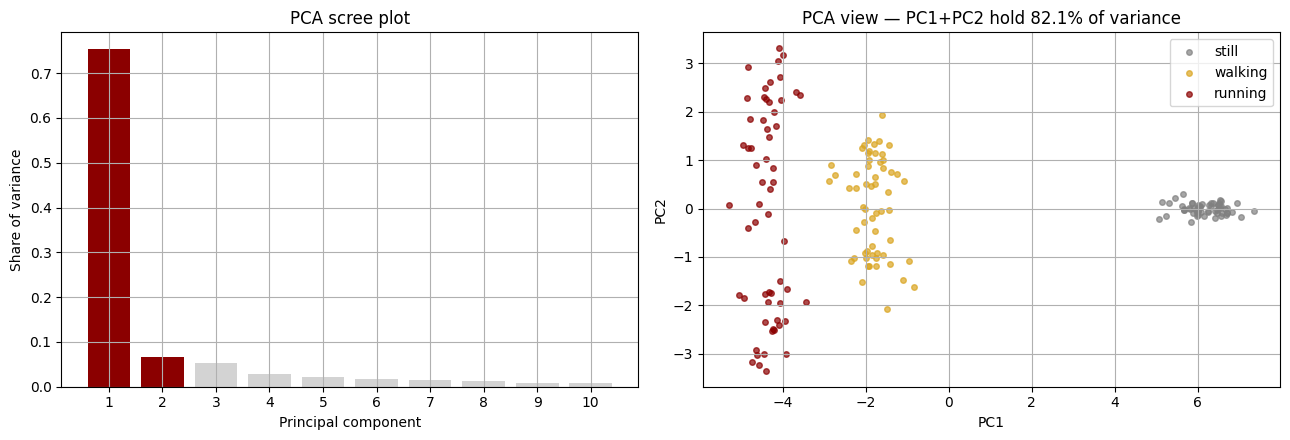

PC1 explains 75.3%; PC2 explains 6.7%.
Together, PC1 and PC2 explain 82.1%.


In [9]:
# Mission 2.1 — standardise, fit PCA, and project onto the first two PCs
scaler = StandardScaler()
Xz = scaler.fit_transform(X)

pca = PCA()
pca.fit(Xz)
Z = pca.transform(Xz)[:, :2]

evr = pca.explained_variance_ratio_
n_show = min(10, len(evr))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(range(1, n_show + 1), evr[:n_show],
            color=["darkred"] * min(2, n_show) + ["lightgrey"] * max(0, n_show - 2))
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Share of variance")
axes[0].set_title("PCA scree plot")
axes[0].set_xticks(range(1, n_show + 1))

for act in COLOURS:
    m = (y == act).values
    if m.any():
        axes[1].scatter(Z[m, 0], Z[m, 1], s=16, alpha=0.7,
                        color=COLOURS[act], label=act)
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].set_title(
    f"PCA view — PC1+PC2 hold {evr[:2].sum():.1%} of variance"
)
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"PC1 explains {evr[0]:.1%}; PC2 explains {evr[1]:.1%}.")
print(f"Together, PC1 and PC2 explain {evr[:2].sum():.1%}.")

In [10]:
# Loadings reader (given) — the axes have meanings; print them
if pca is None:
    print("finish 2.1 first")
else:
    for pc in (0, 1):
        idx = np.argsort(np.abs(pca.components_[pc]))[::-1][:5]
        pretty = ", ".join(f"{X.columns[i]} ({pca.components_[pc][i]:+.2f})" for i in idx)
        print(f"PC{pc+1} ({pca.explained_variance_ratio_[pc]:.0%}) loads on: {pretty}")

PC1 (75%) loads on: az_entropy (+0.22), az_bandE (-0.22), ax_entropy (+0.22), ay_std (-0.22), ax_bandE (-0.22)
PC2 (7%) loads on: ay_mean (+0.70), ax_mean (+0.70), ay_peak_rate (-0.12), ax_peak_rate (+0.07), az_peak_rate (-0.05)


**Q2 — read the axes in your own words (marked):** two sentences, one per PC — what physical
quantity does each axis measure, judging by its top loadings? *(On the reference data PC1 mixes
entropy(+), bandE(−) and std(−) across all axes — one broad “orderly-and-still vs rhythmic-and-violent”
direction holding ~75%. Yours may differ, especially on phone data — read what YOURS says, not what
the reference says.)*

PC1 (75.3% of variance) mainly contrasts spectral entropy, which has positive loadings, with band energy and standard deviation, which have negative loadings across the three axes. It therefore represents a broad difference between more dispersed/complex spectral content and stronger rhythmic or amplitude variation. PC2 (6.7%) is dominated by positive ax_mean and ay_mean loadings, so it mainly reflects the average acceleration level/orientation in the horizontal axes rather than activity intensity alone.


---
## Mission 3 — Deliverable 2: the t-SNE perplexity grid

Six pictures of the same data: perplexity 5 / 30 / 50, seeds 0 and 1.
Only structure that appears in **every** panel earns your trust.


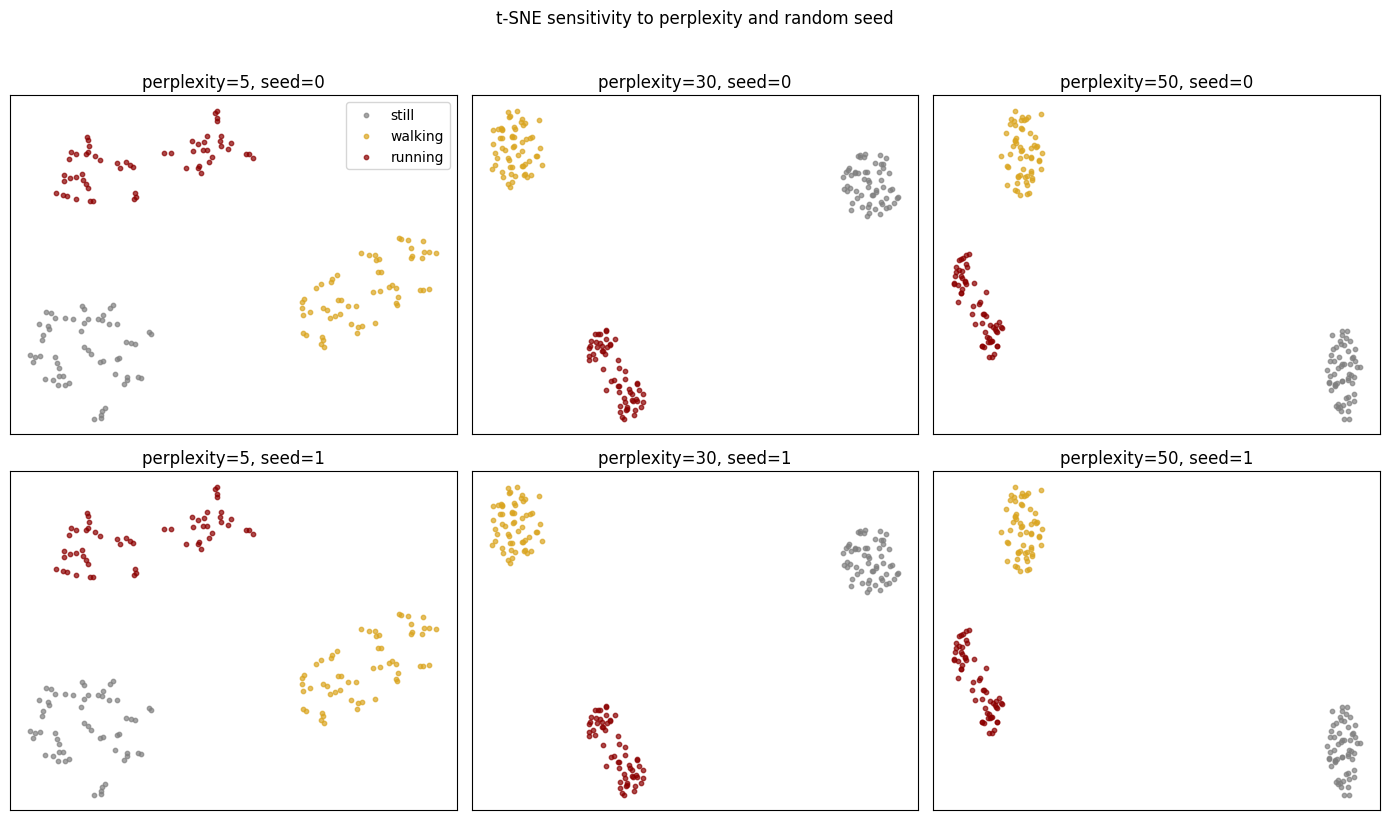

Compare whether the same activity groupings recur in all six panels.
Do not interpret t-SNE axis values, cluster sizes, or inter-cluster distances as physical quantities.


In [12]:
# Mission 3 — six t-SNE projections: 3 perplexities × 2 random seeds
if len(Xz) <= 50:
    raise ValueError("The dataset must contain more than 50 rows for perplexity=50.")

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for row, seed in enumerate((0, 1)):
    for col, perp in enumerate((5, 30, 50)):
        Zt = TSNE(
            n_components=2,
            perplexity=perp,
            random_state=seed,
            init="pca",
            learning_rate="auto",
            max_iter=1000
        ).fit_transform(Xz)

        ax_ = axes[row, col]
        for act in COLOURS:
            m = (y == act).values
            if m.any():
                ax_.scatter(Zt[m, 0], Zt[m, 1], s=10, alpha=0.7,
                            color=COLOURS[act], label=act)
        ax_.set_title(f"perplexity={perp}, seed={seed}")
        ax_.set_xticks([])
        ax_.set_yticks([])

axes[0, 0].legend()
fig.suptitle("t-SNE sensitivity to perplexity and random seed", y=1.02)
plt.tight_layout()
plt.show()
print("Compare whether the same activity groupings recur in all six panels.")
print("Do not interpret t-SNE axis values, cluster sizes, or inter-cluster distances as physical quantities.")

**Q3 — the survival report (one sentence, marked):** what stayed true across all six panels,
and what changed with the knobs?

All six t-SNE panels show three recognisable, largely separate groups corresponding to still, walking and running. The groups' positions, orientations and shapes change with perplexity and random seed, but the three-way separation survives; therefore the class grouping is more trustworthy than the exact geometry of any single projection.

---
## Mission 4 — UMAP *(optional but recommended)*

The modern default. On Colab run the pip line once, restart nothing, re-run this cell.


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


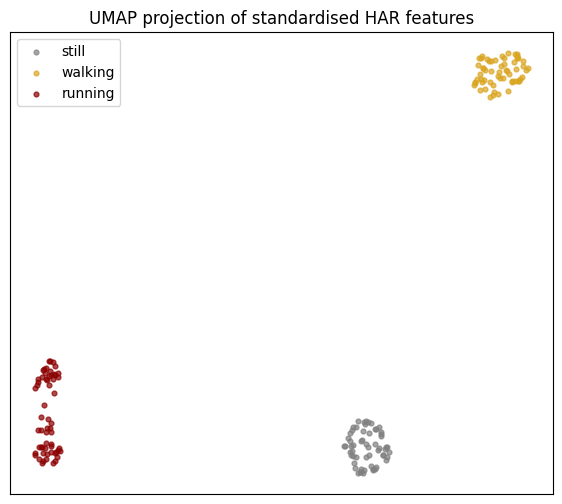

In [14]:

try:
    import umap
    if Xz is not None:
        reducer = umap.UMAP(n_components=2, random_state=0)
        Zu = reducer.fit_transform(Xz)
        plt.figure(figsize=(7, 6))
        for act in COLOURS:
            m = (y == act).values
            if m.any():
                plt.scatter(Zu[m, 0], Zu[m, 1], s=12, alpha=0.7,
                            color=COLOURS[act], label=act)
        plt.title("UMAP projection of standardised HAR features")
        plt.legend()
        plt.xticks([])
        plt.yticks([])
        plt.show()
except ImportError:
    print("umap-learn is not installed. This optional mission can be skipped.")

---
## Mission 5 — Deliverable 3: X-ray your project dataset

Upload your team's feature table as **`project.csv`** (numeric feature columns + one `label`
column — build it with Lab 6's recipe if your data is signals). Then hunt, systematically:

| look for | it appears as |
|---|---|
| mislabelled examples | wrong-coloured points deep inside another island |
| surviving outliers | lone points far from every cloud |
| class overlap | islands that refuse to separate in ANY view |
| duplicates / leakage | suspicious twin points sitting exactly together |


In [16]:
try:
    proj = pd.read_csv("project.csv")
    Xp = proj.drop(columns="label"); yp = proj["label"]
    Xpz = StandardScaler().fit_transform(Xp.values)
    pp = PCA().fit(Xpz); Zp = pp.transform(Xpz)[:, :2]
    plt.figure(figsize=(8, 6))
    for act in sorted(yp.unique()):
        m = (yp == act).values
        plt.scatter(Zp[m, 0], Zp[m, 1], s=14, alpha=0.7, label=str(act))
    plt.title(f"YOUR project — PC1+PC2 hold "
              f"{pp.explained_variance_ratio_[:2].sum():.0%} of variance")
    plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend(); plt.show()
    print("Now the t-SNE sweep on Xpz (copy Mission 3's loop) — then write the X-ray report below.")
except FileNotFoundError:
    print("project.csv not uploaded yet — the template is ready when your team's file is.")

project.csv not found. Upload your team's feature table to complete Mission 5.


**The X-ray report (marked):** list every anomaly you found — row numbers, what the projection
showed, your diagnosis, your fix. If you found none, defend the claim (how hard did you look,
with which views?).

*(write the report here)*


---
## Before you submit (checklist)

- [ ] Whole notebook runs top to bottom — **Runtime → Restart and run all must pass**
- [ ] Mission 1 run and Q1 explains the units failure
- [ ] Mission 2: scree + scatter **with variance % in the title** + Q2's two loading sentences (Deliverable 1)
- [ ] Mission 3: all six panels drawn, Q3's survival sentence (Deliverable 2)
- [ ] Mission 5: project projection + the X-ray report (Deliverable 3)
- [ ] Pushed to your GitHub repository

*Next week: **Machine Learning** — kNN, decision trees, random forests, SVM. The islands you drew
today get borders drawn around them, and your baseline-model milestone lands. Bring har_features.csv
AND project.csv — both get classified.*
